# Gradient Boosting Demystified: XGBoost vs Sklearn GBM
**A Practical Experiment on Tree Depth, Number of Estimators, and Regularization**

---

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – `sklearn.datasets.load_breast_cancer()`  
**Git:** https://github.com/Joryh-IO/XGBoost_vs_GBM

**References:**
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD '16*. https://doi.org/10.1145/2939672.2939785
- Friedman, J.H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.
- Scikit-learn documentation: https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting
- XGBoost documentation: https://xgboost.readthedocs.io

---

## Overview

This tutorial explores two of the most widely used gradient boosting implementations:

1. **Scikit-learn GradientBoostingClassifier** – the classic, interpretable baseline  
2. **XGBoost (XGBClassifier)** – a highly optimised, regularised extension

We focus on three key hyperparameters that every practitioner must understand:

| Hyperparameter | What it controls |
|---|---|
| `n_estimators` | Number of boosting rounds (trees) |
| `max_depth` | Depth of each decision tree |
| Regularisation | L1/L2 penalty on leaf weights (XGBoost) |

By the end of this tutorial, you will understand **what each parameter does**, **how it affects bias-variance trade-off**, and **how to tune it in practice**.

In [1]:
!pip install xgboost scikit-learn pandas numpy matplotlib seaborn

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
    --------------------------------------- 1.6/101.7 MB 9.2 MB/s eta 0:00:11
   - -------------------------------------- 3.4/101.7 MB 8.9 MB/s eta 0:00:11
   -- ------------------------------------- 5.2/101.7 MB 9.0 MB/s eta 0:00:11
   -- ------------------------------------- 7.1/101.7 MB 8.9 MB/s eta 0:00:11
   --- ------------------------------------ 8.9/101.7 MB 8.8 MB/s eta 0:00:11
   ---- ----------------------------------- 10.7/101.7 MB 8.9 MB/s eta 0:00:11
   ---- ----------------------------------- 12.6/101.7 MB 8.8 MB/s eta 0:00:11
   ----- ---------------------------------- 14.4/101.7 MB 8.7 MB/s eta 0:00:10
   ------ --------------------------------- 16.3/101.7 MB 8.8 MB/s eta 0:00:10
   ------- -------------------------------- 18.1/101.7 MB 8.8 MB/s eta 0:00:10
   ------- -------------------------------- 19.9/101.7 MB 8.8 MB/s eta 0:00:10
   -------- ------------------------------- 21.8/101.7 MB 8.8 MB/

## 1. Setup and Imports

In [2]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.colors import ListedColormap

# Machine learning
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
import xgboost as xgb

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Plot style – colour-blind friendly palette
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
CB_COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#CC79A7']

print('All imports successful.')

All imports successful.


## 2. Dataset: Breast Cancer Wisconsin (Diagnostic)

We use the **Breast Cancer Wisconsin** dataset because:
- It is a well-understood binary classification benchmark (malignant / benign)
- Its 30 real-valued features (computed from digitised images of fine needle aspirates) make tree-based models particularly effective
- It is large enough (569 samples) to show genuine generalisation effects without being computationally heavy
- It has no missing values, keeping the focus on the algorithm rather than data cleaning

In [3]:
# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')  # 0 = malignant, 1 = benign

print(f'Dataset shape   : {X.shape}')
print(f'Classes         : {dict(zip(data.target_names, np.bincount(y)))}')
print(f'Class balance   : {np.bincount(y) / len(y)}')
print(f'Missing values  : {X.isnull().sum().sum()}')
X.describe().T[['mean', 'std', 'min', 'max']].head(10)

Dataset shape   : (569, 30)
Classes         : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Class balance   : [0.37258348 0.62741652]
Missing values  : 0


,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


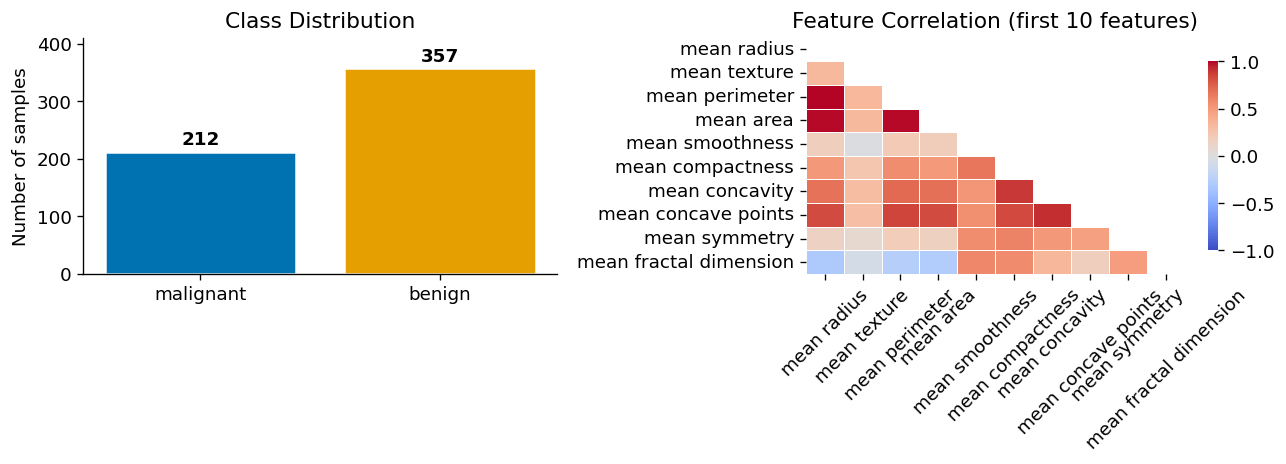

Figure saved: fig_dataset_overview.png


In [4]:
# Visualise class distribution (colour-blind friendly)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Bar chart
counts = np.bincount(y)
bars = axes[0].bar(data.target_names, counts, color=CB_COLORS[:2], edgecolor='white', linewidth=1.5)
for bar, count in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(count), ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Number of samples')
axes[0].set_ylim(0, max(counts) * 1.15)

# Feature correlation heatmap (top 10 features)
top10 = X.iloc[:, :10]
corr = top10.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, ax=axes[1], cmap='coolwarm', vmin=-1, vmax=1,
            annot=False, linewidths=0.3, cbar_kws={'shrink': 0.8})
axes[1].set_title('Feature Correlation (first 10 features)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('fig_dataset_overview.png', bbox_inches='tight')
plt.show()
print('Figure saved: fig_dataset_overview.png')

In [5]:
# Train / test split – stratified to maintain class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f'Train size: {X_train.shape[0]}  |  Test size: {X_test.shape[0]}')
print(f'Train class balance: {np.bincount(y_train)/len(y_train)}')
print(f'Test  class balance: {np.bincount(y_test)/len(y_test)}')

Train size: 455  |  Test size: 114
Train class balance: [0.37362637 0.62637363]
Test  class balance: [0.36842105 0.63157895]


## 3. Background: How Does Gradient Boosting Work?

Gradient boosting builds an ensemble of **weak learners** (shallow decision trees) **sequentially**. Each new tree is trained to correct the errors made by all previous trees.

**The core idea (three steps):**

1. Start with a constant prediction $F_0(x)$ (e.g. the log-odds of the majority class)
2. For each round $m = 1, \ldots, M$:
   - Compute the **pseudo-residuals** (negative gradient of the loss w.r.t. current predictions)
   - Fit a decision tree $h_m(x)$ to these residuals
   - Update: $F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$, where $\eta$ is the **learning rate**
3. Final prediction: $F_M(x)$

**XGBoost** extends this with:
- A regularised objective: $\mathcal{L} = \sum_i \ell(y_i, \hat{y}_i) + \sum_m \Omega(h_m)$
- Where $\Omega(h) = \gamma T + \frac{1}{2}\lambda\|w\|^2 + \alpha\|w\|_1$
- $T$ = number of leaves, $w$ = leaf weights, $\lambda$ = L2 reg, $\alpha$ = L1 reg
- Approximate split-finding for speed on large datasets

## 4. Experiment 1 – Effect of Number of Trees (`n_estimators`)

More trees = more boosting rounds. But too many trees can cause **overfitting** (the model memorises the training data).

We measure **train and test accuracy** as `n_estimators` increases from 1 to 300.

In [6]:
n_tree_values = [1, 5, 10, 20, 30, 50, 75, 100, 150, 200, 250, 300]

results_ntrees = {'n_est': [], 'gbm_train': [], 'gbm_test': [],
                  'xgb_train': [], 'xgb_test': []}

for n in n_tree_values:
    # Sklearn GBM – fixed depth=3
    gbm = GradientBoostingClassifier(n_estimators=n, max_depth=3,
                                     learning_rate=0.1, random_state=SEED)
    gbm.fit(X_train, y_train)

    # XGBoost – fixed depth=3, no extra regularisation
    xgb_clf = xgb.XGBClassifier(n_estimators=n, max_depth=3,
                                  learning_rate=0.1, use_label_encoder=False,
                                  eval_metric='logloss', random_state=SEED,
                                  verbosity=0)
    xgb_clf.fit(X_train, y_train)

    results_ntrees['n_est'].append(n)
    results_ntrees['gbm_train'].append(accuracy_score(y_train, gbm.predict(X_train)))
    results_ntrees['gbm_test'].append(accuracy_score(y_test, gbm.predict(X_test)))
    results_ntrees['xgb_train'].append(accuracy_score(y_train, xgb_clf.predict(X_train)))
    results_ntrees['xgb_test'].append(accuracy_score(y_test, xgb_clf.predict(X_test)))

df_ntrees = pd.DataFrame(results_ntrees)
print(df_ntrees.to_string(index=False))

 n_est  gbm_train  gbm_test  xgb_train  xgb_test
     1   0.626374  0.631579   0.626374  0.631579
     5   0.975824  0.938596   0.960440  0.938596
    10   0.986813  0.929825   0.982418  0.929825
    20   0.993407  0.929825   0.991209  0.947368
    30   0.995604  0.929825   0.991209  0.956140
    50   1.000000  0.947368   0.995604  0.947368
    75   1.000000  0.956140   1.000000  0.947368
   100   1.000000  0.956140   1.000000  0.947368
   150   1.000000  0.956140   1.000000  0.947368
   200   1.000000  0.956140   1.000000  0.947368
   250   1.000000  0.956140   1.000000  0.956140
   300   1.000000  0.956140   1.000000  0.964912


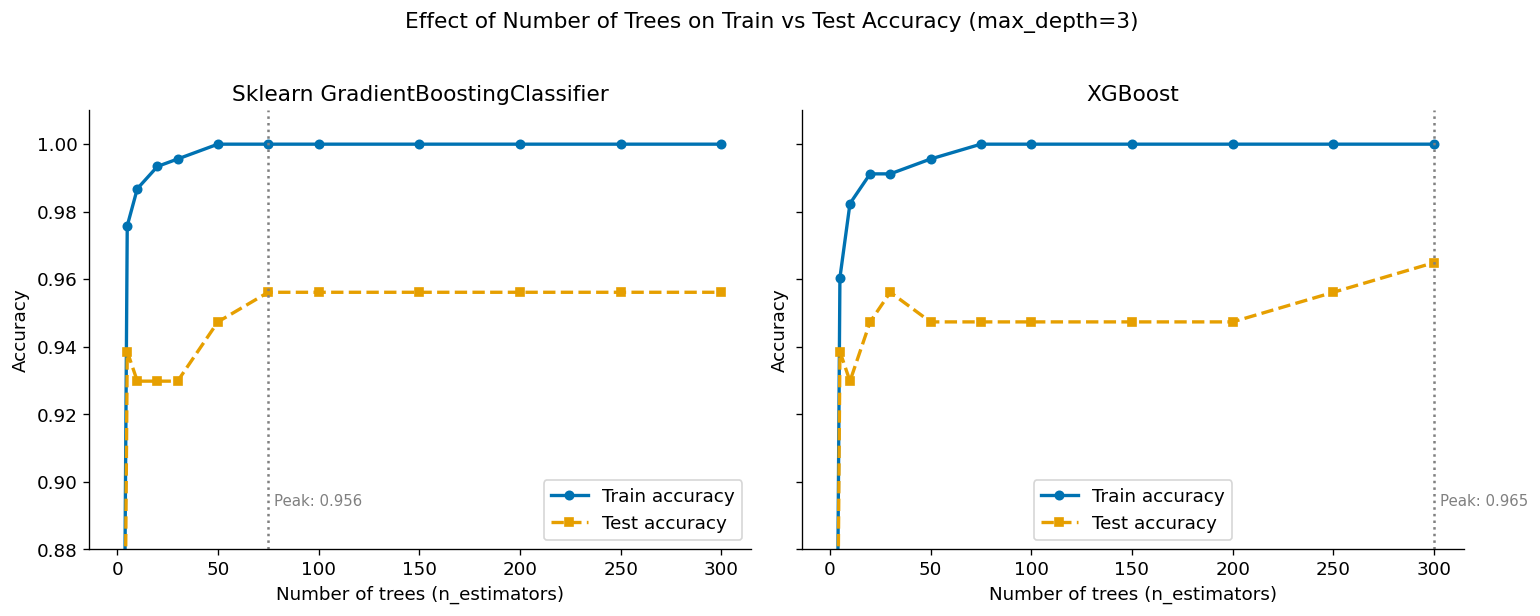

Figure saved: fig_n_estimators.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, model, train_col, test_col, title in zip(
    axes,
    ['Sklearn GBM', 'XGBoost'],
    ['gbm_train', 'xgb_train'],
    ['gbm_test', 'xgb_test'],
    ['Sklearn GradientBoostingClassifier', 'XGBoost']
):
    ax.plot(df_ntrees['n_est'], df_ntrees[train_col],
            color=CB_COLORS[0], lw=2, marker='o', ms=5, label='Train accuracy')
    ax.plot(df_ntrees['n_est'], df_ntrees[test_col],
            color=CB_COLORS[1], lw=2, marker='s', ms=5, linestyle='--', label='Test accuracy')
    ax.set_xlabel('Number of trees (n_estimators)')
    ax.set_ylabel('Accuracy')
    ax.set_title(title)
    ax.legend()
    ax.set_ylim(0.88, 1.01)
    # Annotate peak test accuracy
    best_idx = df_ntrees[test_col].idxmax()
    ax.axvline(df_ntrees['n_est'][best_idx], color='gray', linestyle=':', lw=1.5)
    ax.text(df_ntrees['n_est'][best_idx]+3, 0.893,
            f"Peak: {df_ntrees[test_col][best_idx]:.3f}", color='gray', fontsize=9)

plt.suptitle('Effect of Number of Trees on Train vs Test Accuracy (max_depth=3)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_n_estimators.png', bbox_inches='tight')
plt.show()
print('Figure saved: fig_n_estimators.png')

**Interpretation:**
- Training accuracy rises monotonically as more trees are added — the model can always fit the training data better.
- Test accuracy rises quickly, then **plateaus** or slightly **decreases** — this is the classic bias-variance trade-off.
- XGBoost tends to plateau more gracefully due to its built-in regularisation.

## 5. Experiment 2 – Effect of Tree Depth (`max_depth`)

Tree depth controls the **complexity** of each weak learner:
- **Shallow trees** (depth 1–2): high bias, low variance — underfitting risk
- **Deep trees** (depth 6+): low bias, high variance — overfitting risk

Gradient boosting typically uses shallow trees (`max_depth = 3–5`) because the ensemble corrects bias over multiple rounds.

In [8]:
depth_values = [1, 2, 3, 4, 5, 6, 7, 8]

results_depth = {'depth': [], 'gbm_train': [], 'gbm_test': [],
                 'xgb_train': [], 'xgb_test': []}

for d in depth_values:
    gbm = GradientBoostingClassifier(n_estimators=100, max_depth=d,
                                     learning_rate=0.1, random_state=SEED)
    gbm.fit(X_train, y_train)

    xgb_clf = xgb.XGBClassifier(n_estimators=100, max_depth=d,
                                  learning_rate=0.1, use_label_encoder=False,
                                  eval_metric='logloss', random_state=SEED,
                                  verbosity=0)
    xgb_clf.fit(X_train, y_train)

    results_depth['depth'].append(d)
    results_depth['gbm_train'].append(accuracy_score(y_train, gbm.predict(X_train)))
    results_depth['gbm_test'].append(accuracy_score(y_test, gbm.predict(X_test)))
    results_depth['xgb_train'].append(accuracy_score(y_train, xgb_clf.predict(X_train)))
    results_depth['xgb_test'].append(accuracy_score(y_test, xgb_clf.predict(X_test)))

df_depth = pd.DataFrame(results_depth)
print(df_depth.to_string(index=False))

 depth  gbm_train  gbm_test  xgb_train  xgb_test
     1   0.991209  0.956140   0.986813  0.956140
     2   1.000000  0.947368   1.000000  0.956140
     3   1.000000  0.956140   1.000000  0.947368
     4   1.000000  0.947368   1.000000  0.947368
     5   1.000000  0.938596   1.000000  0.947368
     6   1.000000  0.894737   1.000000  0.947368
     7   1.000000  0.912281   1.000000  0.947368
     8   1.000000  0.912281   1.000000  0.947368


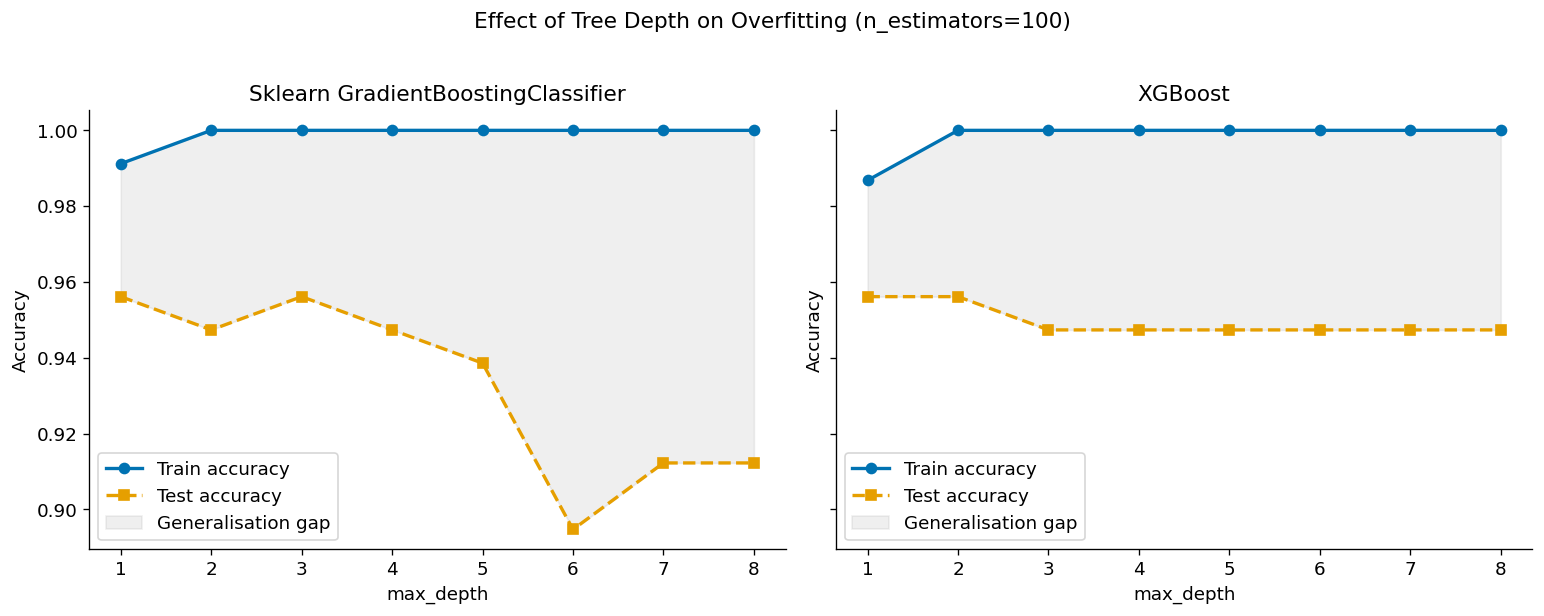

Figure saved: fig_tree_depth.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, train_col, test_col, title in zip(
    axes,
    ['gbm_train', 'xgb_train'],
    ['gbm_test', 'xgb_test'],
    ['Sklearn GradientBoostingClassifier', 'XGBoost']
):
    ax.plot(df_depth['depth'], df_depth[train_col],
            color=CB_COLORS[0], lw=2, marker='o', ms=6, label='Train accuracy')
    ax.plot(df_depth['depth'], df_depth[test_col],
            color=CB_COLORS[1], lw=2, marker='s', ms=6, linestyle='--', label='Test accuracy')
    ax.fill_between(df_depth['depth'],
                    df_depth[train_col], df_depth[test_col],
                    alpha=0.12, color='gray', label='Generalisation gap')
    ax.set_xlabel('max_depth')
    ax.set_ylabel('Accuracy')
    ax.set_title(title)
    ax.set_xticks(depth_values)
    ax.legend()

plt.suptitle('Effect of Tree Depth on Overfitting (n_estimators=100)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_tree_depth.png', bbox_inches='tight')
plt.show()
print('Figure saved: fig_tree_depth.png')

**Interpretation:**
- As depth increases, training accuracy quickly saturates at 100% — the model perfectly memorises training data.
- The **generalisation gap** (grey shaded area) widens with depth, indicating overfitting.
- `max_depth = 3` is typically the sweet spot for gradient boosting — consistent with Friedman's original recommendation.
- XGBoost maintains a **smaller generalisation gap** at all depths due to regularisation.

## 6. Experiment 3 – Regularisation in XGBoost

XGBoost offers three regularisation parameters not available in sklearn's GBM:

| Parameter | Type | Effect |
|---|---|---|
| `reg_lambda` (λ) | L2 (Ridge) | Shrinks leaf weights — reduces variance |
| `reg_alpha` (α) | L1 (Lasso) | Drives leaf weights to zero — sparsity |
| `gamma` (γ) | Min loss reduction | Pruning — only split if gain ≥ γ |

We compare four regularisation configurations at a depth likely to overfit (`max_depth=6`).

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

reg_configs = [
    {'label': 'No regularisation\n(λ=0, α=0, γ=0)',
     'params': dict(reg_lambda=0, reg_alpha=0, gamma=0)},
    {'label': 'L2 only\n(λ=5, α=0, γ=0)',
     'params': dict(reg_lambda=5, reg_alpha=0, gamma=0)},
    {'label': 'L1 only\n(λ=0, α=2, γ=0)',
     'params': dict(reg_lambda=0, reg_alpha=2, gamma=0)},
    {'label': 'L1 + L2 + gamma\n(λ=3, α=1, γ=0.5)',
     'params': dict(reg_lambda=3, reg_alpha=1, gamma=0.5)},
]

reg_results = []
for cfg in reg_configs:
    model = xgb.XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1,
        use_label_encoder=False, eval_metric='logloss',
        random_state=SEED, verbosity=0, **cfg['params']
    )
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    model.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc  = accuracy_score(y_test,  model.predict(X_test))
    reg_results.append({
        'Config': cfg['label'],
        'Train Acc': train_acc,
        'Test Acc': test_acc,
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std()
    })

df_reg = pd.DataFrame(reg_results)
print(df_reg.to_string(index=False))

                            Config  Train Acc  Test Acc  CV Mean   CV Std
No regularisation\n(λ=0, α=0, γ=0)   1.000000  0.938596 0.963096 0.010220
          L2 only\n(λ=5, α=0, γ=0)   0.997802  0.947368 0.957833 0.010188
          L1 only\n(λ=0, α=2, γ=0)   0.995604  0.956140 0.961341 0.008922
L1 + L2 + gamma\n(λ=3, α=1, γ=0.5)   0.993407  0.947368 0.956078 0.014642


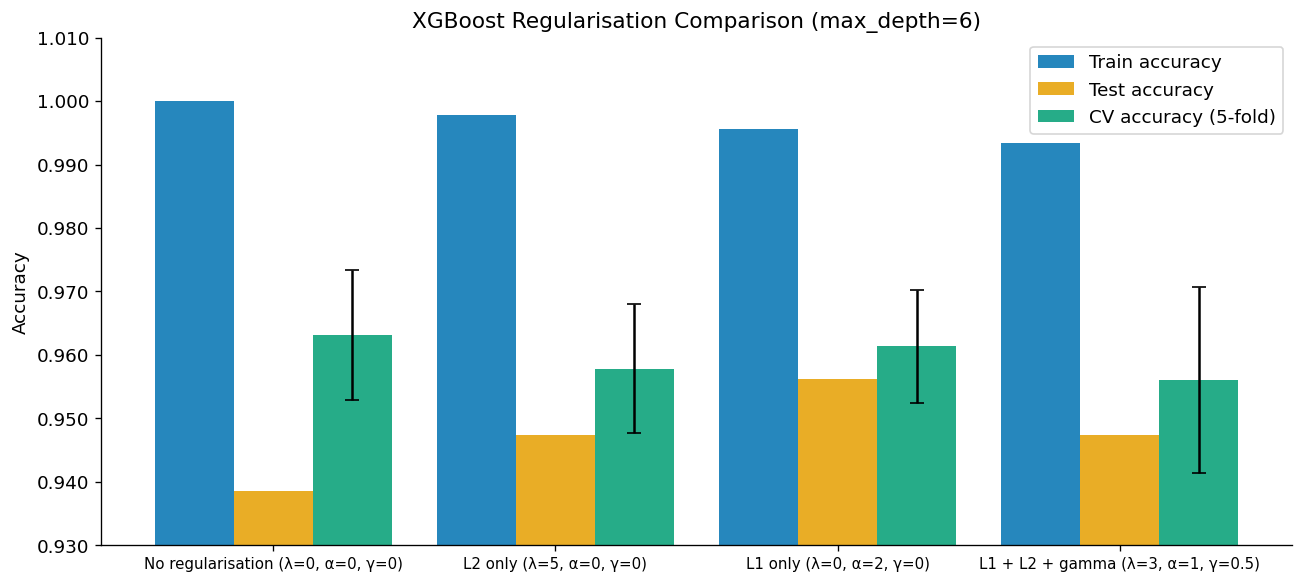

Figure saved: fig_regularisation.png


In [11]:
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(df_reg))
w = 0.28
labels = [c.replace('\n', ' ') for c in df_reg['Config']]

b1 = ax.bar(x - w, df_reg['Train Acc'], width=w, color=CB_COLORS[0], label='Train accuracy', alpha=0.85)
b2 = ax.bar(x,     df_reg['Test Acc'],  width=w, color=CB_COLORS[1], label='Test accuracy',  alpha=0.85)
b3 = ax.bar(x + w, df_reg['CV Mean'],   width=w, color=CB_COLORS[2], label='CV accuracy (5-fold)', alpha=0.85)

# Error bars for CV
ax.errorbar(x + w, df_reg['CV Mean'], yerr=df_reg['CV Std'],
            fmt='none', ecolor='black', capsize=4, elinewidth=1.5)

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('Accuracy')
ax.set_ylim(0.93, 1.01)
ax.set_title('XGBoost Regularisation Comparison (max_depth=6)')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.3f}'))

plt.tight_layout()
plt.savefig('fig_regularisation.png', bbox_inches='tight')
plt.show()
print('Figure saved: fig_regularisation.png')

**Interpretation:**
- Without regularisation, the model achieves near-perfect training accuracy but generalises slightly worse.
- L2 regularisation (`reg_lambda`) reduces the generalisation gap by penalising large leaf weights.
- L1 + L2 + gamma provides the best overall cross-validated score, demonstrating how combined regularisation prevents overfitting at high tree depth.

## 7. Best Model Selection and Final Evaluation

Based on the experiments above, we select the best configuration for each algorithm and compare them on the held-out test set.

In [12]:
# Best Sklearn GBM – n_estimators=100, max_depth=3
best_gbm = GradientBoostingClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.1,
    subsample=0.8, random_state=SEED
)
best_gbm.fit(X_train, y_train)

# Best XGBoost – n_estimators=100, max_depth=3, with regularisation
best_xgb = xgb.XGBClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.1,
    reg_lambda=3, reg_alpha=1, gamma=0.5,
    subsample=0.8, use_label_encoder=False,
    eval_metric='logloss', random_state=SEED, verbosity=0
)
best_xgb.fit(X_train, y_train)

# Evaluate
models = {'Sklearn GBM': best_gbm, 'XGBoost': best_xgb}
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    print(f"=== {name} ===")
    print(f"  Accuracy : {accuracy_score(y_test, y_pred):.4f}")
    print(f"  ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")
    print(f"  F1-Score : {f1_score(y_test, y_pred):.4f}")
    print()

=== Sklearn GBM ===
  Accuracy : 0.9474
  ROC-AUC  : 0.9940
  F1-Score : 0.9589

=== XGBoost ===
  Accuracy : 0.9474
  ROC-AUC  : 0.9940
  F1-Score : 0.9589



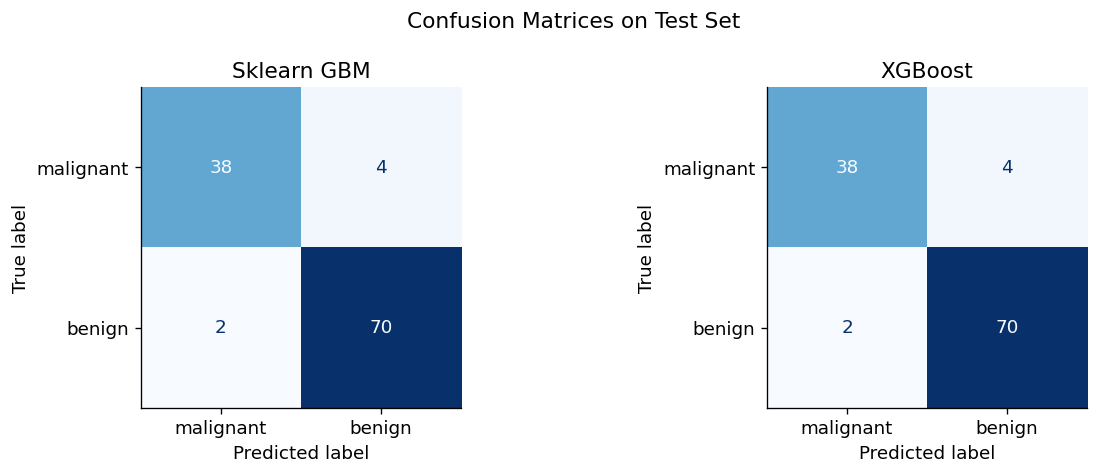

Figure saved: fig_confusion_matrices.png


In [13]:
# Confusion matrices – side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=data.target_names)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)

plt.suptitle('Confusion Matrices on Test Set', fontsize=13)
plt.tight_layout()
plt.savefig('fig_confusion_matrices.png', bbox_inches='tight')
plt.show()
print('Figure saved: fig_confusion_matrices.png')

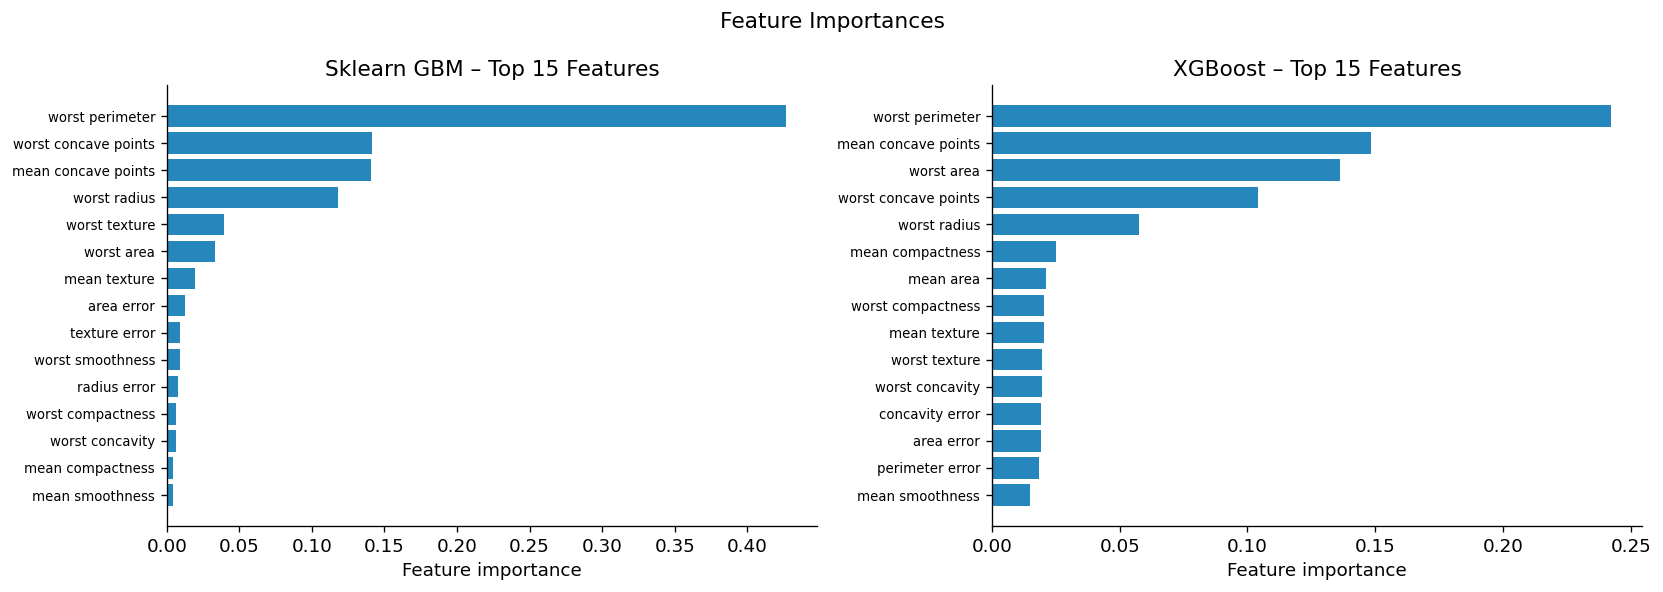

Figure saved: fig_feature_importance.png


In [14]:
# Feature importance – top 15 features for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
n_top = 15

for ax, (name, model) in zip(axes, models.items()):
    importances = model.feature_importances_
    indices = np.argsort(importances)[-n_top:]
    ax.barh(range(n_top), importances[indices], color=CB_COLORS[0], alpha=0.85)
    ax.set_yticks(range(n_top))
    ax.set_yticklabels([data.feature_names[i] for i in indices], fontsize=8)
    ax.set_xlabel('Feature importance')
    ax.set_title(f'{name} – Top {n_top} Features')

plt.suptitle('Feature Importances', fontsize=13)
plt.tight_layout()
plt.savefig('fig_feature_importance.png', bbox_inches='tight')
plt.show()
print('Figure saved: fig_feature_importance.png')

## 8. Summary Table

In [15]:
summary_rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    summary_rows.append({
        'Model': name,
        'n_estimators': 100,
        'max_depth': 3,
        'Regularisation': 'None' if name == 'Sklearn GBM' else 'λ=3, α=1, γ=0.5',
        'Test Accuracy': f"{accuracy_score(y_test, y_pred):.4f}",
        'ROC-AUC': f"{roc_auc_score(y_test, y_prob):.4f}",
        'F1-Score': f"{f1_score(y_test, y_pred):.4f}",
    })

pd.DataFrame(summary_rows).set_index('Model')

,n_estimators,max_depth,Regularisation,Test Accuracy,ROC-AUC,F1-Score
Model,,,,,,
Sklearn GBM,100,3,None,0.9474,0.9940,0.9589
XGBoost,100,3,"λ=3, α=1, γ=0.5",0.9474,0.9940,0.9589


## 9. Key Takeaways

| Finding | Practical advice |
|---|---|
| More trees help up to a point | Start with 100–200; use early stopping for large datasets |
| max_depth = 3 is the sweet spot | Shallower than random forests; gradient boosting corrects bias via rounds |
| Regularisation closes the gap | Use XGBoost's λ and α especially when depth > 4 |
| XGBoost vs sklearn GBM | XGBoost is faster and more regularised; sklearn GBM is simpler to understand |
